In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
def gerar_dados_seno(n_amostras=1000):
  """gera dados da função seno com um pouco de ruído."""
  X = np.linspace(0, 2*np.pi, n_amostras).reshape(-1,1)
  y = np.sin(X).ravel()
  # Adicionando um pequeno ruído para tornar o desafio mais real
  y += 0.1 * np.random.randn(n_amostras)
  return X, y

X, y = gerar_dados_seno()

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Total de amostras: {len(X)}")

Total de amostras: 1000


In [ ]:
modelo_mlp = Sequential([
  tf.keras.Input(shape=(1,)),
  Dense(100, activation='tanh'),
  Dense(50, activation='tanh'),
  Dense(1)
])

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
funcao_perda = tf.keras.losses.MeanSquaredError()
modelo_mlp.compile(optimizer=optimizer, loss=funcao_perda)

historico = modelo_mlp.fit(
    X_treino, y_treino,
  epochs=200,
  batch_size=32,
  validation_split=0.1
)

Epoch 1/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4403 - val_loss: 0.3201
Epoch 2/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2313 - val_loss: 0.1885
Epoch 3/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1741 - val_loss: 0.1559
Epoch 4/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1622 - val_loss: 0.1495
Epoch 5/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1575 - val_loss: 0.1408
Epoch 6/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1505 - val_loss: 0.1340
Epoch 7/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1417 - val_loss: 0.1293
Epoch 8/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1416 - val_loss: 0.1279
Epoch 9/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1319 - val_loss: 0.1149
Epoch 10/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1197 - val_loss: 0.1032
Epoch 11/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1129 - val_loss: 0.0936
Epoch 12/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

<function matplotlib.pyplot.show(close=None, block=None)>

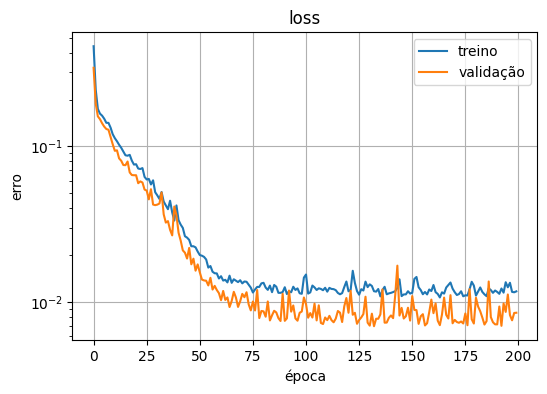

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(historico.history['loss'], label='treino')
plt.plot(historico.history['val_loss'], label='validação')
plt.title('loss')
plt.xlabel('época')
plt.ylabel('erro')
plt.legend()
plt.yscale('log')
plt.grid(True)
plt.show

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


<function matplotlib.pyplot.show(close=None, block=None)>

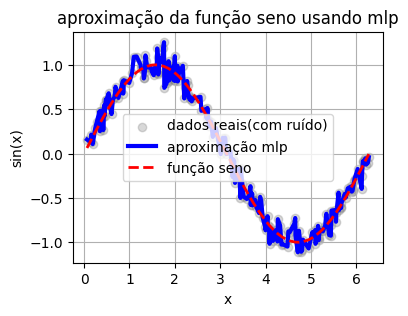

In [ ]:
y_predito = modelo_mlp.predict(X_teste).flatten()

#visualização
indices_ordenados = np.argsort(X_teste.ravel())
X_plot = X_teste[indices_ordenados]
y_plot = y_teste[indices_ordenados]

plt.figure(figsize=(4, 3))
plt.scatter(X_teste, y_teste, color='gray', alpha=0.3, label='dados reais(com ruído)')
plt.plot(X_plot, y_plot, color='blue', linewidth=3, label='aproximação mlp')
plt.plot(X_plot, np.sin(X_plot), color='red', linewidth=2, linestyle='--', label='função seno')

plt.title('aproximação da função seno usando mlp')
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.legend()
plt.grid(True)
plt.show

In [ ]:
loss = modelo_mlp.evaluate(X_teste, y_teste, verbose=0)
print(f'Erro médio quadrático (MSE): {loss:.4f}')

mse = mean_squared_error(y_teste, y_predito)
mae = mean_absolute_error(y_teste, y_predito)
r2 = r2_score(y_teste, y_predito)
print(f"Erro Absoluto Médio (MAE): {mae:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.4f}")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")

Erro médio quadrático (MSE): 0.0115
Erro Absoluto Médio (MAE): 0.0871
Erro Quadrático Médio (MSE): 0.0115
Coeficiente de Determinação (R²): 0.9782
